# Scaling

### There are two types of scaling: i) Standardization and ii) Normalization.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [2]:
data = {
    "Age": [20, 22, 25, 35, 45, 52, 23, 40, 60, 50],
    "Salary": [20000, 25000, 30000, 80000, 90000, 120000, 27000, 70000, 150000, 100000],
    "Purchased": [0, 0, 0, 1, 1, 1, 0, 1, 1, 1]
}

data = pd.DataFrame(data)

print(data)

   Age  Salary  Purchased
0   20   20000          0
1   22   25000          0
2   25   30000          0
3   35   80000          1
4   45   90000          1
5   52  120000          1
6   23   27000          0
7   40   70000          1
8   60  150000          1
9   50  100000          1


In [3]:
X = data[["Age", "Salary"]]
y = data['Purchased']
print(X)
print(y)

   Age  Salary
0   20   20000
1   22   25000
2   25   30000
3   35   80000
4   45   90000
5   52  120000
6   23   27000
7   40   70000
8   60  150000
9   50  100000
0    0
1    0
2    0
3    1
4    1
5    1
6    0
7    1
8    1
9    1
Name: Purchased, dtype: int64


In [4]:
x_train, x_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=42)

In [5]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(x_train, y_train)

y_pred = knn.predict(x_test)

print(f"Accuracy without scaling : {accuracy_score(y_test,y_pred)}")

Accuracy without scaling : 1.0


In [6]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_test)

print(x_train_scaled)
print(x_test_scaled)

[[-1.29986737 -1.28992177]
 [ 0.55708601  0.33994328]
 [-0.83562902 -0.96394876]
 [ 1.48556271  1.31786231]
 [ 1.02132436  0.9918893 ]
 [ 0.09284767  0.66591629]
 [-1.02132436 -1.06174066]]
[[ 0.93741002  0.96969743]
 [-1.38573655 -1.37634474]
 [ 0.44832653  0.40664731]]


In [7]:
knn.fit(x_train_scaled, y_train)

y_pred_scaled = knn.predict(x_test_scaled)
print(f"Accuracy with scaling : {accuracy_score(y_test, y_pred)}")

Accuracy with scaling : 1.0


In [8]:
scale_data = pd.DataFrame(
    x_train_scaled,
    columns = ["Age", "Salary"]
)

print(scale_data)

        Age    Salary
0 -1.299867 -1.289922
1  0.557086  0.339943
2 -0.835629 -0.963949
3  1.485563  1.317862
4  1.021324  0.991889
5  0.092848  0.665916
6 -1.021324 -1.061741


In [9]:
# Made some changes in purchased

data2 = {
    "Age": [20, 22, 25, 35, 45, 52, 23, 40, 60, 50],
    "Salary": [20000, 25000, 30000, 80000, 950000, 120000, 27000, 70000, 170000, 100000],
    "Purchased": [0, 1, 1, 0, 1, 1, 0, 0, 0, 1]
}

In [10]:
X2 = data[["Age", "Salary"]]
y2 = data['Purchased']
print(X2)
print(y2)

   Age  Salary
0   20   20000
1   22   25000
2   25   30000
3   35   80000
4   45   90000
5   52  120000
6   23   27000
7   40   70000
8   60  150000
9   50  100000
0    0
1    0
2    0
3    1
4    1
5    1
6    0
7    1
8    1
9    1
Name: Purchased, dtype: int64


In [11]:
x_train2, x_test2, y_train2, y_test2 = train_test_split(X2, y2, train_size=0.7, random_state=42)

In [12]:
knn = KNeighborsClassifier(n_neighbors=3)

knn.fit(x_train2, y_train2)

y_pred2 = knn.predict(x_test2)

print(f"Accuracy without scaling : {accuracy_score(y_test2,y_pred2)}")

Accuracy without scaling : 1.0


# Feature Scaling

In [13]:
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [14]:
data3 = sns.load_dataset("titanic")
data3.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [15]:
data3.shape

(891, 15)

In [16]:
data3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [17]:
data3_n = data3[["survived", "pclass", "age", "parch"]]
data3_n.head()

,survived,pclass,age,parch
0,0,3,22.0,0
1,1,1,38.0,0
2,1,3,26.0,0
3,1,1,35.0,0
4,0,3,35.0,0


In [18]:
data3_n.isnull().sum()

survived      0
pclass        0
age         177
parch         0
dtype: int64

In [20]:
data3_n.describe()

,survived,pclass,age,parch
count,891.000000,891.000000,714.000000,891.000000
mean,0.383838,2.308642,29.699118,0.381594
std,0.486592,0.836071,14.526497,0.806057
min,0.000000,1.000000,0.420000,0.000000
25%,0.000000,2.000000,20.125000,0.000000
50%,0.000000,3.000000,28.000000,0.000000
75%,1.000000,3.000000,38.000000,0.000000
max,1.000000,3.000000,80.000000,6.000000


In [23]:
data3_n_fill = data3_n.fillna(data3_n.mean())
data3_n_fill

,survived,pclass,age,parch
0,0,3,22.000000,0
1,1,1,38.000000,0
2,1,3,26.000000,0
3,1,1,35.000000,0
4,0,3,35.000000,0
...,...,...,...,...
886,0,2,27.000000,0
887,1,1,19.000000,0
888,0,3,29.699118,2
889,1,1,26.000000,0


In [24]:
x3 = data3_n_fill.drop(columns= ['survived'])
y3 = data3_n_fill['survived']

In [25]:
x_train3, x_test3, y_train3, y_test3 = train_test_split(x3, y3, train_size= 0.7, random_state=42)

In [26]:
print(f"shape of x_train : {x_train3.shape}")
print(f"shape of x_test : {x_test3.shape}")
print(f"shape of y_train : {y_train3.shape}")
print(f"shape of y_test : {y_test3.shape}")

shape of x_train : (623, 3)
shape of x_test : (268, 3)
shape of y_train : (623,)
shape of y_test : (268,)


In [27]:
st = StandardScaler()

st.fit(x_train3)

,copy,True
,with_mean,True
,with_std,True


In [29]:
st.mean_

array([ 2.34189406, 29.34447927,  0.38683788])

In [30]:
st.scale_

array([ 0.81928654, 13.01755249,  0.8070437 ])

In [31]:
x_train3.describe()

,pclass,age,parch
count,623.000000,623.000000,623.000000
mean,2.341894,29.344479,0.386838
std,0.819945,13.028013,0.807692
min,1.000000,0.420000,0.000000
25%,2.000000,22.000000,0.000000
50%,3.000000,29.699118,0.000000
75%,3.000000,35.000000,0.000000
max,3.000000,80.000000,6.000000


In [33]:
x_train3_sc = st.transform(x_train3)
print(x_train3_sc)

[[-1.63788124 -1.94694658  1.99885349]
 [ 0.80326712  0.02724309 -0.47932706]
 [ 0.80326712 -2.17740465  0.75976322]
 ...
 [ 0.80326712  0.8953696  -0.47932706]
 [-1.63788124 -1.17875302  1.99885349]
 [-1.63788124 -0.64101752  0.75976322]]


In [35]:
x_test3_sc = st.transform(x_test3)
print(x_test3_sc)

[[ 0.80326712  0.02724309  0.75976322]
 [-0.41730706  0.12717604 -0.47932706]
 [ 0.80326712 -0.71783688 -0.47932706]
 [-0.41730706 -1.79330787  0.75976322]
 [ 0.80326712 -1.17875302 -0.47932706]
 [-1.63788124 -0.25692074 -0.47932706]
 [ 0.80326712  0.02724309 -0.47932706]
 [ 0.80326712 -1.0251143  -0.47932706]
 [ 0.80326712 -1.0251143  -0.47932706]
 [-1.63788124 -0.79465624  1.99885349]
 [-1.63788124  0.58809217 -0.47932706]
 [ 0.80326712  1.12582766 -0.47932706]
 [ 0.80326712  0.02724309  0.75976322]
 [ 0.80326712  0.05035668 -0.47932706]
 [-0.41730706  0.51127282 -0.47932706]
 [-1.63788124 -1.0251143   0.75976322]
 [-1.63788124  0.97218895 -0.47932706]
 [ 0.80326712  0.02724309 -0.47932706]
 [-0.41730706 -0.18010139 -0.47932706]
 [-1.63788124  1.35628573 -0.47932706]
 [ 0.80326712 -0.41055946 -0.47932706]
 [-1.63788124  0.3576341  -0.47932706]
 [ 0.80326712 -0.79465624 -0.47932706]
 [ 0.80326712 -0.71783688 -0.47932706]
 [ 0.80326712  0.02724309 -0.47932706]
 [ 0.80326712 -1.48603044

In [36]:
x_train3

,pclass,age,parch
445,1,4.000000,2
650,3,29.699118,0
172,3,1.000000,1
450,2,36.000000,2
314,2,43.000000,1
...,...,...,...
106,3,21.000000,0
270,1,29.699118,0
860,3,41.000000,0
435,1,14.000000,2


In [37]:
x_train3_sc = pd.DataFrame(x_train3_sc, columns = ["pclass", "age", "parch"])
x_train3_sc

,pclass,age,parch
0,-1.637881,-1.946947,1.998853
1,0.803267,0.027243,-0.479327
2,0.803267,-2.177405,0.759763
3,-0.417307,0.511273,1.998853
4,-0.417307,1.049008,0.759763
...,...,...,...
618,0.803267,-0.641018,-0.479327
619,-1.637881,0.027243,-0.479327
620,0.803267,0.895370,-0.479327
621,-1.637881,-1.178753,1.998853


In [57]:
x_test3_sc = pd.DataFrame(x_test3_sc, columns = ["pclass", "age", "parch"])
x_test3_sc

,pclass,age,parch
0,-1.637881,-1.946947,1.998853
1,0.803267,0.027243,-0.479327
2,0.803267,-2.177405,0.759763
3,-0.417307,0.511273,1.998853
4,-0.417307,1.049008,0.759763
...,...,...,...
618,0.803267,-0.641018,-0.479327
619,-1.637881,0.027243,-0.479327
620,0.803267,0.895370,-0.479327
621,-1.637881,-1.178753,1.998853


In [58]:
x_train3_sc.describe()

,pclass,age,parch
count,6.230000e+02,6.230000e+02,6.230000e+02
mean,2.537653e-16,-4.562072e-17,-5.702590e-18
std,1.000804e+00,1.000804e+00,1.000804e+00
min,-1.637881e+00,-2.221960e+00,-4.793271e-01
25%,-4.173071e-01,-5.641982e-01,-4.793271e-01
50%,8.032671e-01,2.724309e-02,-4.793271e-01
75%,8.032671e-01,4.344535e-01,-4.793271e-01
max,8.032671e-01,3.891324e+00,6.955215e+00


In [59]:
x_train3_sc.describe().round()

,pclass,age,parch
count,623.0,623.0,623.0
mean,0.0,-0.0,-0.0
std,1.0,1.0,1.0
min,-2.0,-2.0,-0.0
25%,-0.0,-1.0,-0.0
50%,1.0,0.0,-0.0
75%,1.0,0.0,-0.0
max,1.0,4.0,7.0


In [60]:
x_test3_sc.describe().round()

,pclass,age,parch
count,623.0,623.0,623.0
mean,0.0,-0.0,-0.0
std,1.0,1.0,1.0
min,-2.0,-2.0,-0.0
25%,-0.0,-1.0,-0.0
50%,1.0,0.0,-0.0
75%,1.0,0.0,-0.0
max,1.0,4.0,7.0


## MinMaxScaler

In [61]:
mms = MinMaxScaler()

In [62]:
mms.fit(x_train3)

,feature_range,"(0, ...)"
,copy,True
,clip,False


In [63]:
x_train3_mmc = mms.transform(x_train3)
x_train3_mmc

array([[0.        , 0.04498618, 0.33333333],
       [1.        , 0.36792055, 0.        ],
       [1.        , 0.00728826, 0.16666667],
       ...,
       [1.        , 0.50992712, 0.        ],
       [0.        , 0.17064589, 0.33333333],
       [0.        , 0.25860769, 0.16666667]], shape=(623, 3))

In [64]:
x_test3_mmc = mms.transform(x_test3)
x_test3_mmc

array([[1.        , 0.36792055, 0.16666667],
       [0.5       , 0.3842674 , 0.        ],
       [1.        , 0.24604172, 0.        ],
       [0.5       , 0.07011812, 0.16666667],
       [1.        , 0.17064589, 0.        ],
       [0.        , 0.32143755, 0.        ],
       [1.        , 0.36792055, 0.        ],
       [1.        , 0.19577783, 0.        ],
       [1.        , 0.19577783, 0.        ],
       [0.        , 0.23347575, 0.33333333],
       [0.        , 0.45966323, 0.        ],
       [1.        , 0.54762503, 0.        ],
       [1.        , 0.36792055, 0.16666667],
       [1.        , 0.37170143, 0.        ],
       [0.5       , 0.44709726, 0.        ],
       [0.        , 0.19577783, 0.16666667],
       [0.        , 0.52249309, 0.        ],
       [1.        , 0.36792055, 0.        ],
       [0.5       , 0.33400352, 0.        ],
       [0.        , 0.58532295, 0.        ],
       [1.        , 0.2963056 , 0.        ],
       [0.        , 0.42196532, 0.        ],
       [1.

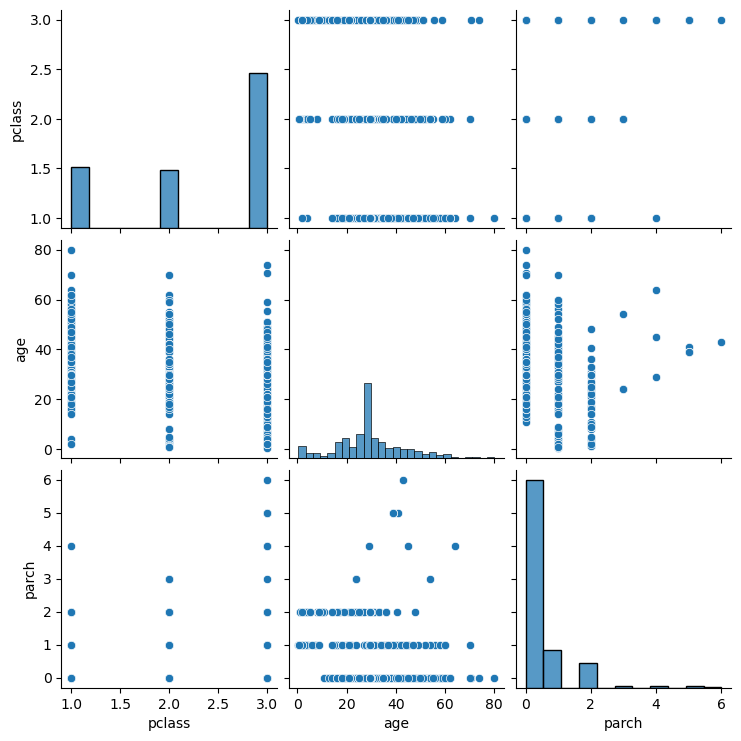

In [71]:
sns.pairplot(x_train3)

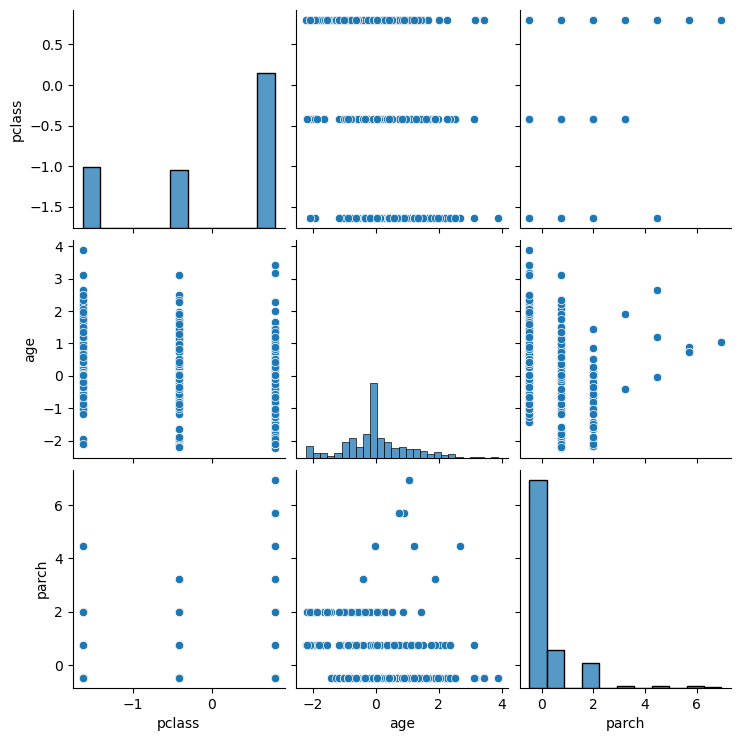

In [67]:
sns.pairplot(x_train3_sc)

In [68]:
x_train3_mmc = pd.DataFrame(x_train3_mmc, columns = ["pclass", "age", "parch"])
x_train3_mmc

,pclass,age,parch
0,0.0,0.044986,0.333333
1,1.0,0.367921,0.000000
2,1.0,0.007288,0.166667
3,0.5,0.447097,0.333333
4,0.5,0.535059,0.166667
...,...,...,...
618,1.0,0.258608,0.000000
619,0.0,0.367921,0.000000
620,1.0,0.509927,0.000000
621,0.0,0.170646,0.333333


In [69]:
x_test3_mmc = pd.DataFrame(x_test3_mmc, columns = ["pclass", "age", "parch"])
x_test3_mmc

,pclass,age,parch
0,1.0,0.367921,0.166667
1,0.5,0.384267,0.000000
2,1.0,0.246042,0.000000
3,0.5,0.070118,0.166667
4,1.0,0.170646,0.000000
...,...,...,...
263,1.0,0.334004,0.000000
264,0.0,0.367921,0.000000
265,0.0,0.811510,0.000000
266,1.0,0.208344,0.000000


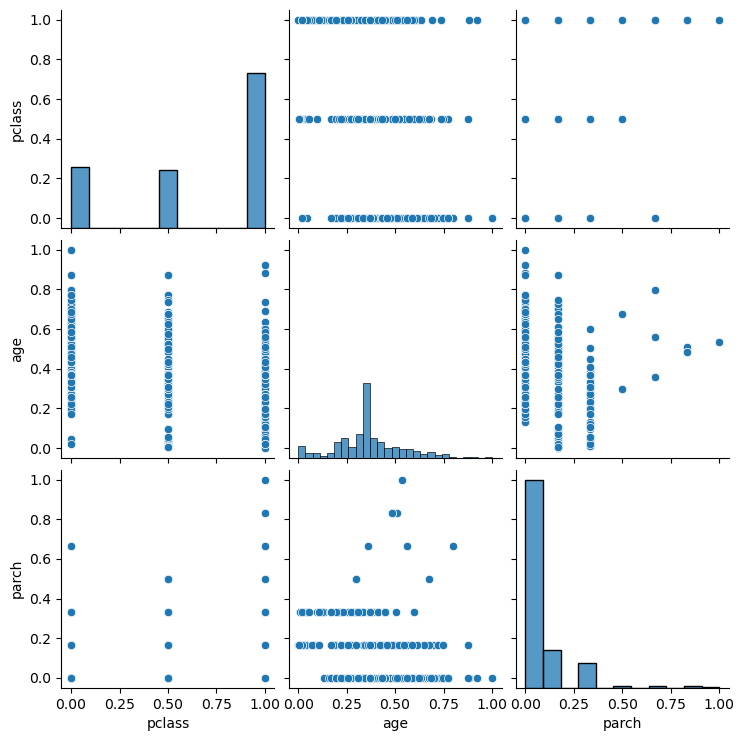

In [56]:
sns.pairplot(x_train3_mmc)